In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

df = pd.read_csv('station_day_clean.csv')
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')

print(df.shape)
df.head()


(86754, 19)


,StationId,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI,AQI_Bucket,Year,Month,Season,State
0,AP001,2017-11-25,81.40,124.50,1.44,20.50,12.08,10.72,0.12,15.24,127.09,0.20,6.50,184,Moderate,2017,11,Post-Monsoon,AP
1,AP001,2017-11-26,78.32,129.06,1.26,26.00,14.85,10.28,0.14,26.96,117.44,0.22,7.95,197,Moderate,2017,11,Post-Monsoon,AP
2,AP001,2017-11-27,88.76,135.32,6.60,30.85,21.77,12.91,0.11,33.59,111.81,0.29,7.63,198,Moderate,2017,11,Post-Monsoon,AP
3,AP001,2017-11-28,64.18,104.09,2.56,28.07,17.01,11.42,0.09,19.00,138.18,0.17,5.02,188,Moderate,2017,11,Post-Monsoon,AP
4,AP001,2017-11-29,72.47,114.84,5.23,23.20,16.59,12.25,0.16,10.55,109.74,0.21,4.71,173,Moderate,2017,11,Post-Monsoon,AP


In [3]:
print('Missing values :', df.isnull().sum().sum())
print('Duplicate rows :', df.duplicated().sum())
print('Date range     :', df['Date'].min().date(), 'to', df['Date'].max().date())
print('Stations       :', df['StationId'].nunique())
print('States         :', df['State'].nunique())
df.describe().T.round(2)


Missing values : 0
Duplicate rows : 0
Date range     : 2015-01-01 to 2020-07-01
Stations       : 109
States         : 21


,count,mean,min,25%,50%,75%,max,std
Date,86754,2018-11-25 08:06:03.510616,2015-01-01 00:00:00,2018-04-20 00:00:00,2019-03-05 00:00:00,2019-11-21 00:00:00,2020-07-01 00:00:00,NaN
PM2.5,86754.0,79.031217,0.04,32.76,56.35,97.6875,418.09405,71.924096
PM10,86754.0,147.981727,0.03,88.6625,118.65,171.6,617.3635,105.098896
NO,86754.0,22.901753,0.02,4.89,10.36,24.59,203.3635,33.34765
NO2,86754.0,34.827344,0.01,15.22,27.12,46.66,164.5635,27.654034
NOx,86754.0,42.238738,0.0,15.7725,27.32,50.69,255.1247,43.534923
NH3,86754.0,26.63662,0.01,17.13,23.66,30.13,126.06645,18.022772
CO,86754.0,1.508462,0.0,0.61,0.95,1.46,30.1041,2.966493
SO2,86754.0,11.74194,0.01,5.46,8.98,14.12,80.74705,10.636871
O3,86754.0,36.821905,0.01,20.28,30.2,44.75,281.2194,30.727337


In [4]:
poor_days = df['AQI_Bucket'].isin(['Poor', 'Very Poor', 'Severe'])
vp_days   = df['AQI_Bucket'].isin(['Very Poor', 'Severe'])

kpi = pd.DataFrame({
    'KPI': ['Total station-day records', 'Monitoring stations', 'Average AQI',
            'Median AQI', 'Average PM2.5 (ug/m3)', '% days Poor or worse',
            '% days Very Poor or Severe'],
    'Value': [f"{len(df):,}", df['StationId'].nunique(), round(df['AQI'].mean(), 1),
              df['AQI'].median(), round(df['PM2.5'].mean(), 1),
              round(poor_days.mean() * 100, 1), round(vp_days.mean() * 100, 1)]
})
kpi


,KPI,Value
0,Total station-day records,"86,754"
1,Monitoring stations,109
2,Average AQI,176.8
3,Median AQI,133.0
4,Average PM2.5 (ug/m3),79.0
5,% days Poor or worse,32.7
6,% days Very Poor or Severe,19.5


In [5]:
state_tbl = df.groupby('State').agg(
    avg_aqi=('AQI', 'mean'),
    avg_pm25=('PM2.5', 'mean'),
    stations=('StationId', 'nunique'),
    records=('AQI', 'size')
).round(1)

state_tbl['pct_poor_or_worse'] = (
    df.assign(p=poor_days).groupby('State')['p'].mean() * 100
).round(1)

state_tbl = state_tbl.sort_values('avg_aqi', ascending=False)

# Use only states with 2+ stations for a fair ranking
reliable = state_tbl[state_tbl['stations'] >= 2]
print('Top 5 states:');    print(reliable.head(5))
print('Cleanest 5 states:'); print(reliable.tail(5))


Top 5 states:
       avg_aqi  avg_pm25  stations  records  pct_poor_or_worse
State                                                         
DL       235.4     109.2        37    36010               53.7
UP       216.1     109.1         5     5226               49.4
BR       215.2     104.8         6     2117               45.3
HR       210.2     103.2         4     2324               45.2
OD       161.5      62.6         2     1402               25.6
Cleanest 5 states:
       avg_aqi  avg_pm25  stations  records  pct_poor_or_worse
State                                                         
AP       108.1      43.6         2     2007                7.3
MH       103.1      36.4        10     3867                8.6
TG       100.1      43.9         6     7005                2.2
KA        91.8      39.8        10     9584                3.0
KL        79.8      27.8         4     1477                0.4


In [6]:
season_order = ['Winter', 'Summer', 'Monsoon', 'Post-Monsoon']
season_tbl = df.groupby('Season')[['AQI', 'PM2.5', 'PM10']].mean().round(1).loc[season_order]
print(season_tbl)
print('Winter / Monsoon ratio:', round(season_tbl.loc['Winter', 'AQI'] / season_tbl.loc['Monsoon', 'AQI'], 1))

month_tbl = df.groupby('Month')[['AQI', 'PM2.5']].mean().round(1)
month_tbl


                AQI  PM2.5   PM10
Season                           
Winter        239.2  121.1  186.5
Summer        157.7   61.6  139.2
Monsoon       114.0   40.4  104.0
Post-Monsoon  230.7  116.3  185.7
Winter / Monsoon ratio: 2.1


,AQI,PM2.5
Month,,
1,248.6,127.7
2,209.9,95.5
3,159.1,66.3
4,155.6,59.4
5,158.4,59.1
6,132.1,47.9
7,109.3,37.8
8,101.8,34.4
9,105.9,38.5


In [7]:
pollutants = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'AQI']
corr = df[pollutants].corr()
corr['AQI'].drop('AQI').sort_values(ascending=False).round(2)


PM2.5      0.86
PM10       0.73
NO2        0.51
NOx        0.51
NO         0.50
NH3        0.38
CO         0.37
SO2        0.34
Toluene    0.30
Benzene    0.19
O3         0.18
Name: AQI, dtype: float64

In [8]:
# Yearly trend (note: number of stations grows every year)
year_tbl = df.groupby('Year').agg(avg_aqi=('AQI', 'mean'), stations=('StationId', 'nunique')).round(1)
print(year_tbl)

# Delhi only - fairer long-term view
delhi_year = df[df['State'] == 'DL'].groupby('Year')['AQI'].mean().round(1)
print(delhi_year)

# Lockdown: compare Jan-Jun 2019 vs 2020 on the SAME stations only
common = set(df[df['Year'] == 2019]['StationId']) & set(df[df['Year'] == 2020]['StationId'])
cmp = df[df['StationId'].isin(common) & df['Year'].isin([2019, 2020]) & (df['Month'] <= 6)]

res = cmp.groupby('Year')['AQI'].mean().round(1)
print('Stations compared:', len(common))
print(res)
print('Overall change %:', round((res[2020] / res[2019] - 1) * 100, 1))

mm = cmp.pivot_table(index='Month', columns='Year', values='AQI').round(1)
mm['change_%'] = ((mm[2020] / mm[2019] - 1) * 100).round(1)
mm


      avg_aqi  stations
Year                   
2015    219.2        21
2016    203.5        24
2017    199.1        47
2018    195.3        77
2019    172.5       101
2020    134.9       107
Year
2015    295.9
2016    287.6
2017    314.8
2018    243.4
2019    229.4
2020    183.4
Name: AQI, dtype: float64
Stations compared: 99
Year
2019    191.0
2020    137.0
Name: AQI, dtype: float64
Overall change %: -28.3


Year,2019,2020,change_%
Month,,,
1,274.3,216.0,-21.3
2,207.1,190.2,-8.2
3,169.1,117.4,-30.6
4,175.5,93.9,-46.5
5,181.2,107.8,-40.5
6,141.6,90.3,-36.2


In [9]:
station_avg = df.groupby('StationId')['AQI'].mean().sort_values(ascending=False).round(1)
print('Most polluted stations:');  print(station_avg.head(5))
print('Cleanest stations:');        print(station_avg.tail(5))


Most polluted stations:
StationId
GJ001    356.3
DL002    331.0
DL028    293.0
DL038    264.1
DL020    260.4
Name: AQI, dtype: float64
Cleanest stations:
StationId
MH006    68.6
KA010    68.2
KL007    67.2
ML001    53.8
MZ001    34.8
Name: AQI, dtype: float64


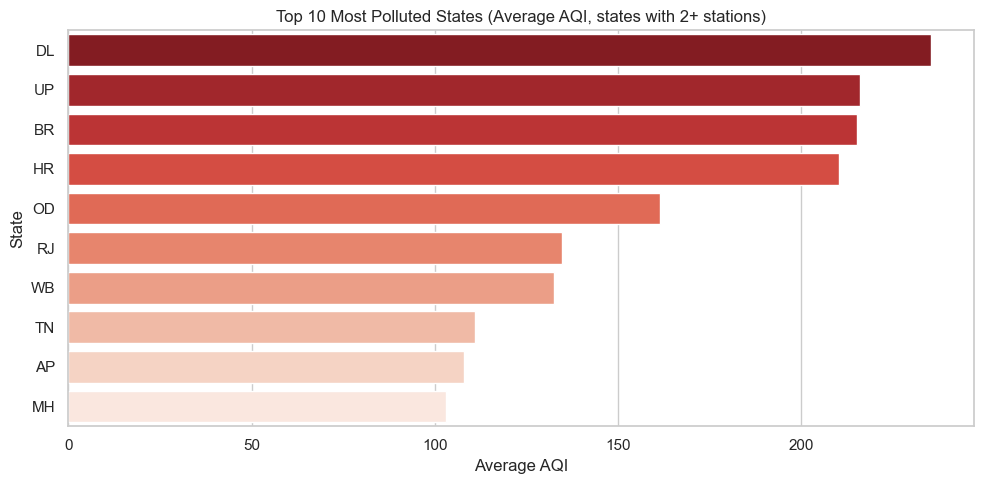

In [10]:
top10 = reliable.head(10).reset_index()
plt.figure()
sns.barplot(data=top10, x='avg_aqi', y='State', palette='Reds_r')
plt.title('Top 10 Most Polluted States (Average AQI, states with 2+ stations)')
plt.xlabel('Average AQI')
plt.ylabel('State')
plt.tight_layout()
plt.savefig('chart1_states.png', dpi=150)
plt.show()


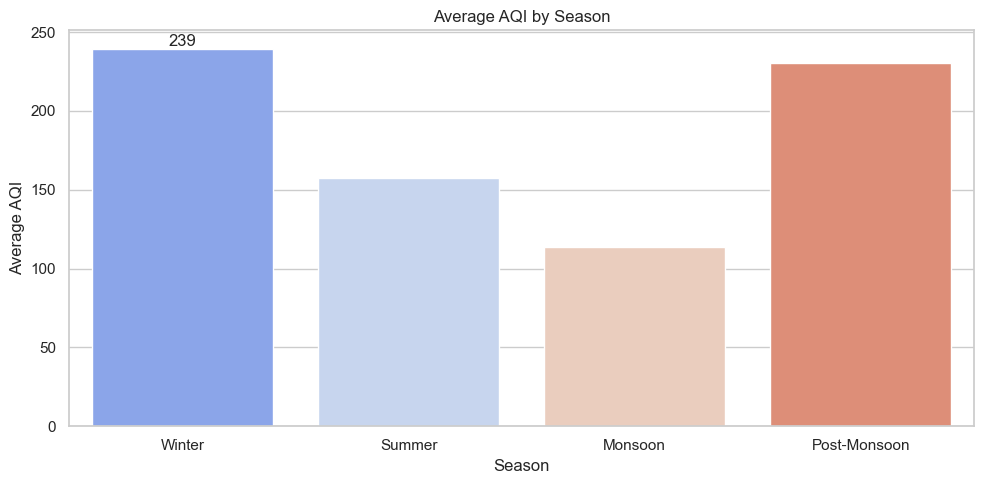

In [11]:
plt.figure()
ax = sns.barplot(x=season_tbl.index, y=season_tbl['AQI'], palette='coolwarm')
ax.bar_label(ax.containers[0], fmt='%.0f')
plt.title('Average AQI by Season')
plt.xlabel('Season')
plt.ylabel('Average AQI')
plt.tight_layout()
plt.savefig('chart2_season.png', dpi=150)
plt.show()


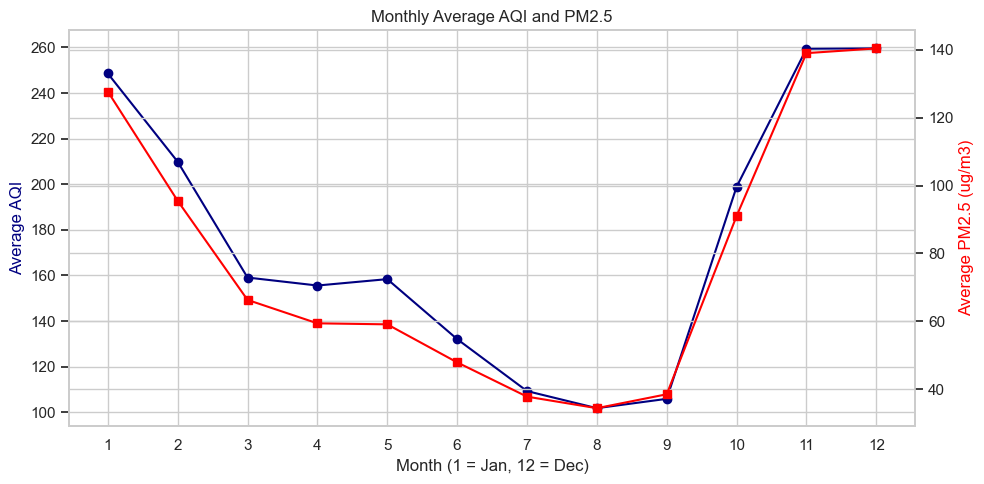

In [12]:
fig, ax1 = plt.subplots()
ax1.plot(month_tbl.index, month_tbl['AQI'], marker='o', color='navy', label='AQI')
ax1.set_xlabel('Month (1 = Jan, 12 = Dec)')
ax1.set_ylabel('Average AQI', color='navy')
ax1.set_xticks(range(1, 13))

ax2 = ax1.twinx()
ax2.plot(month_tbl.index, month_tbl['PM2.5'], marker='s', color='red', label='PM2.5')
ax2.set_ylabel('Average PM2.5 (ug/m3)', color='red')

plt.title('Monthly Average AQI and PM2.5')
fig.tight_layout()
plt.savefig('chart3_monthly.png', dpi=150)
plt.show()


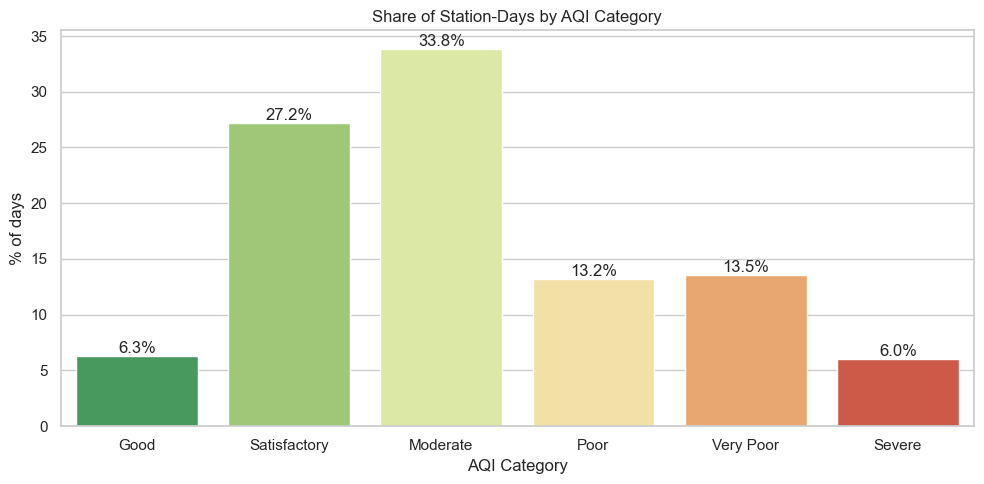

In [13]:
order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
pct = df['AQI_Bucket'].value_counts(normalize=True).reindex(order) * 100

plt.figure()
ax = sns.barplot(x=pct.index, y=pct.values, palette='RdYlGn_r')
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%')
plt.title('Share of Station-Days by AQI Category')
plt.xlabel('AQI Category')
plt.ylabel('% of days')
plt.tight_layout()
plt.savefig('chart4_buckets.png', dpi=150)
plt.show()


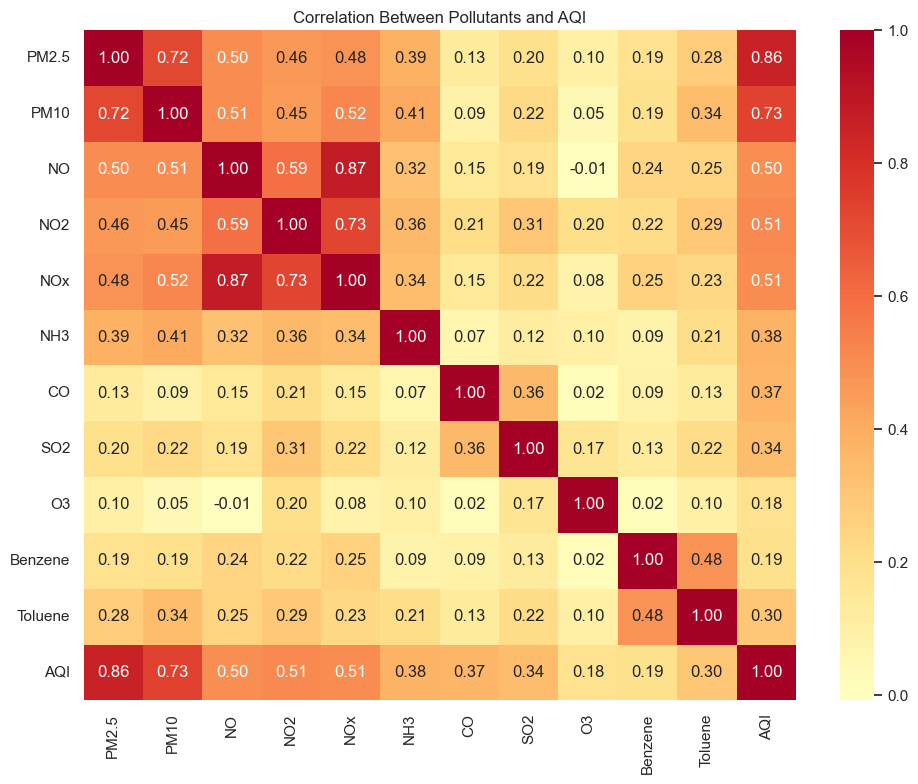

In [14]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn_r', center=0)
plt.title('Correlation Between Pollutants and AQI')
plt.tight_layout()
plt.savefig('chart5_corr.png', dpi=150)
plt.show()


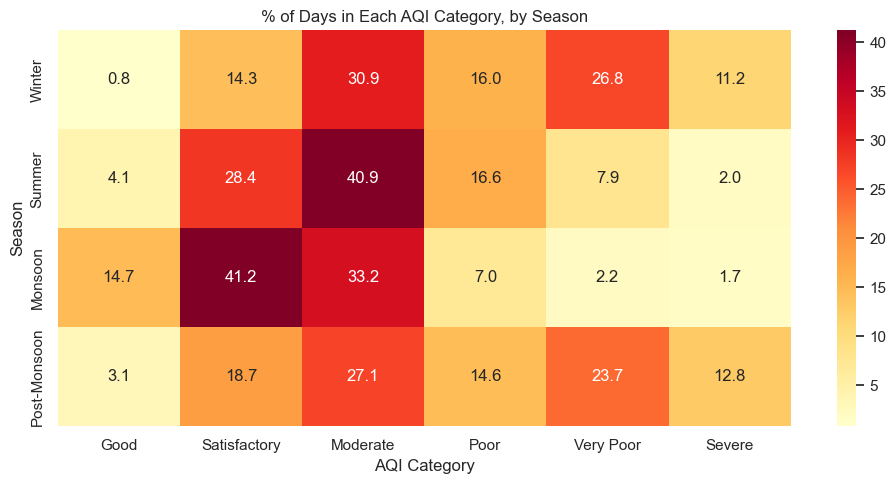

In [15]:
ct = (pd.crosstab(df['Season'], df['AQI_Bucket'], normalize='index') * 100).round(1)
ct = ct[order].loc[season_order]

plt.figure()
sns.heatmap(ct, annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('% of Days in Each AQI Category, by Season')
plt.xlabel('AQI Category')
plt.ylabel('Season')
plt.tight_layout()
plt.savefig('chart6_season_bucket.png', dpi=150)
plt.show()


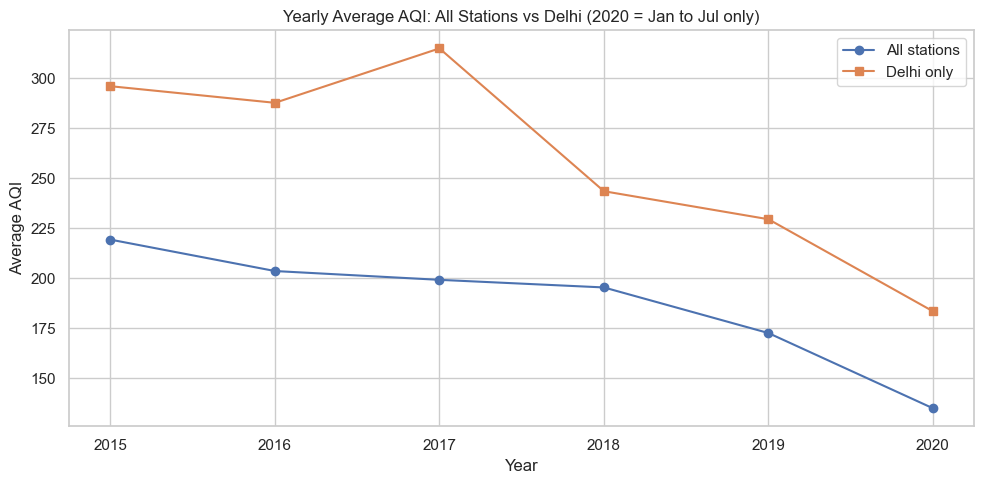

In [16]:
plt.figure()
plt.plot(year_tbl.index, year_tbl['avg_aqi'], marker='o', label='All stations')
plt.plot(delhi_year.index, delhi_year.values, marker='s', label='Delhi only')
plt.title('Yearly Average AQI: All Stations vs Delhi (2020 = Jan to Jul only)')
plt.xlabel('Year')
plt.ylabel('Average AQI')
plt.legend()
plt.tight_layout()
plt.savefig('chart7_yearly.png', dpi=150)
plt.show()
